In [2]:
import sys
from pathlib import Path

project_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file()
    and (path / "data" / "raw" / "SECOND_train_set").is_dir()
)
sys.path.insert(0, str(project_root))

from src.datasets.second_dataset import PALETTE, make_val_loader

val_loader = make_val_loader(
    project_root / "data" / "raw" / "SECOND_train_set"
)
x1, x2, y1, y2 = next(iter(val_loader))

print("Validation pairs:", len(val_loader.dataset.pair_names))
print("First pair:", val_loader.dataset.pair_names[0])
print("Validation patches:", len(val_loader.dataset))
print("Image batch:", tuple(x1.shape))
print("Mask batch:", tuple(y1.shape))

Validation pairs: 594
First pair: 01610.png
Validation patches: 2376
Image batch: (4, 3, 256, 256)
Mask batch: (4, 256, 256)


In [16]:
import importlib
import src.models.siamese as siamese

importlib.reload(siamese)

from src.models.siamese import SiameseHybrid, SiameseResNet18, SiameseTransformer

print(SiameseHybrid.__name__)

SiameseHybrid


In [13]:
import torch

from src.models.siamese import SiameseHybrid, SiameseResNet18, SiameseTransformer

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_classes = len(PALETTE)
checkpoint_dir = project_root / "outputs" / "checkpoints"

runs = [
    ("ResNet18", SiameseResNet18, "resnet18_weighted_epoch3.pt"),
    ("Transformer", SiameseTransformer, "transformer_weighted_epoch3.pt"),
    ("Hybrid", SiameseHybrid, "hybrid_weighted_epoch3.pt"),
]

for name, _, filename in runs:
    path = checkpoint_dir / filename
    if not path.is_file():
        raise FileNotFoundError(path)
    print(f"{name}: checkpoint found")

ResNet18: checkpoint found
Transformer: checkpoint found
Hybrid: checkpoint found


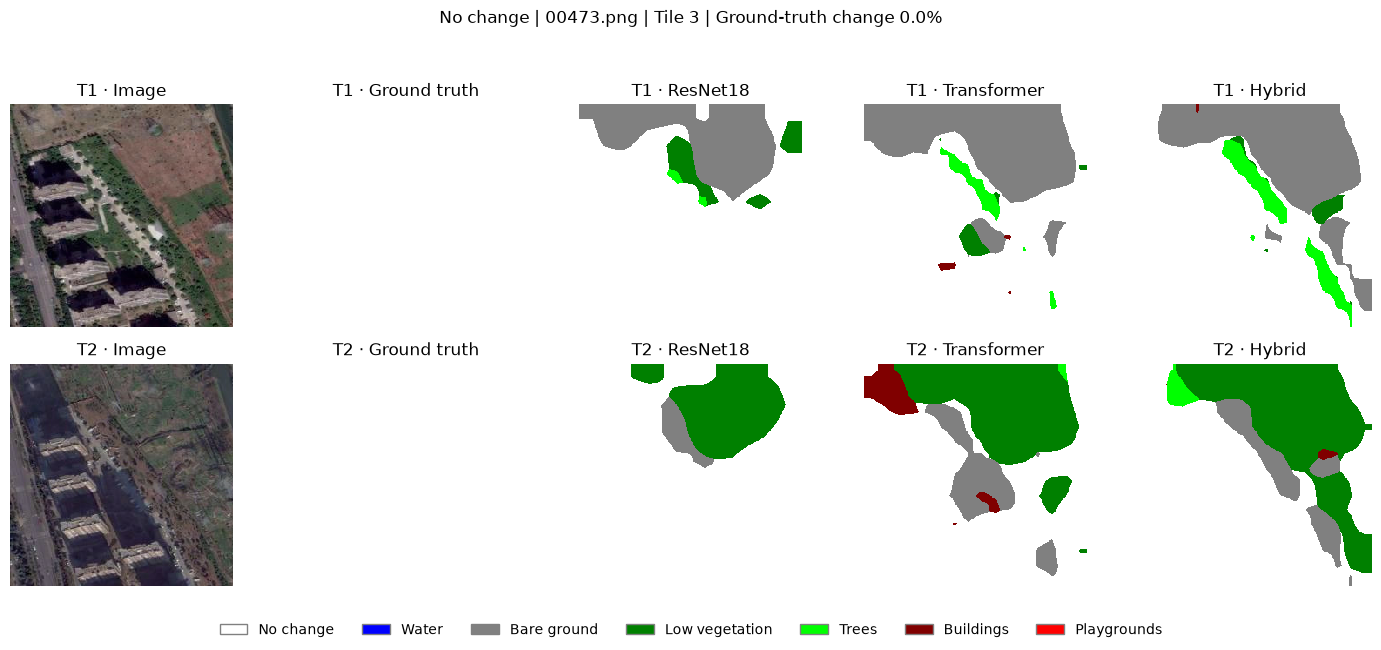

Saved to c:\Users\Ittikorn\Music\TerraMind\outputs\figures\no_change_00473_tile3.png


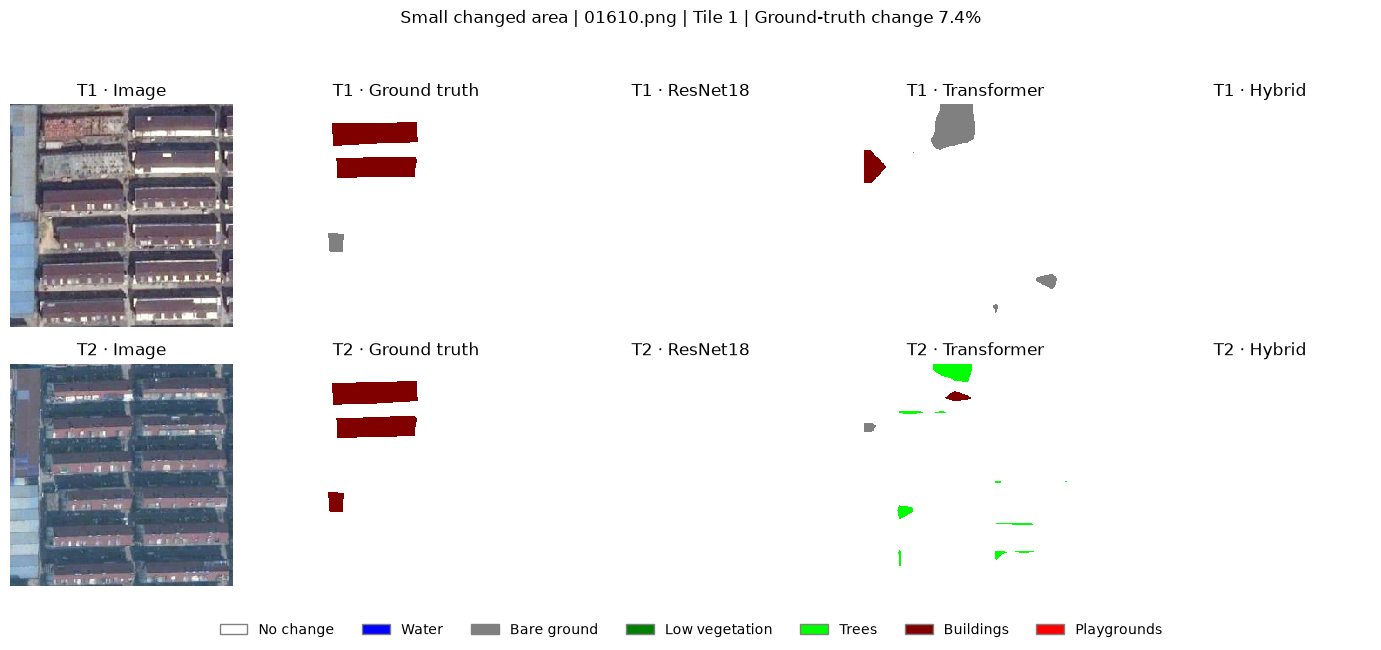

Saved to c:\Users\Ittikorn\Music\TerraMind\outputs\figures\small_changed_area_01610_tile1.png


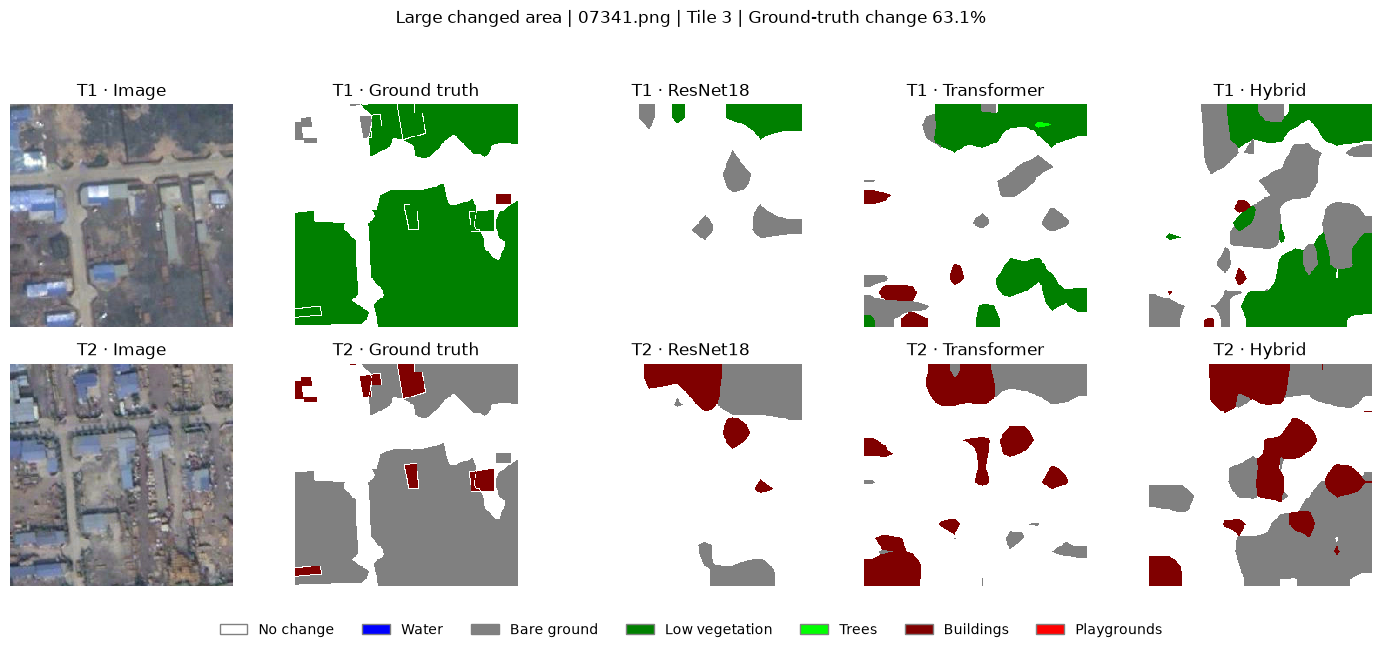

Saved to c:\Users\Ittikorn\Music\TerraMind\outputs\figures\large_changed_area_07341_tile3.png


In [15]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

case_names = ("No change", "Small changed area", "Large changed area")
examples = {}
sample_index = 0

for image1, image2, target1, target2 in val_loader:
    changed = (target1 != 0) | (target2 != 0)
    fractions = changed.float().mean(dim=(1, 2)).tolist()

    for i, fraction in enumerate(fractions):
        if fraction == 0:
            case = case_names[0]
        elif fraction <= 0.15:
            case = case_names[1]
        elif fraction >= 0.50:
            case = case_names[2]
        else:
            continue

        if case not in examples:
            pair_index, tile = divmod(sample_index + i, 4)
            pair_name = val_loader.dataset.pair_names[pair_index]
            examples[case] = (
                pair_name, tile, image1[i], image2[i],
                target1[i], target2[i], fraction,
            )

    if len(examples) == len(case_names):
        break
    sample_index += image1.size(0)

assert len(examples) == 3, f"Found only: {list(examples)}"

predictions = {case: {} for case in case_names}

with torch.inference_mode():
    for name, model_class, filename in runs:
        checkpoint = torch.load(
            checkpoint_dir / filename, map_location="cpu", weights_only=True,
        )
        model = model_class(num_classes=num_classes)
        model.load_state_dict(checkpoint["model_state_dict"])
        model = model.to(device).eval()

        for case in case_names:
            _, _, x1, x2, _, _, _ = examples[case]
            logits1, logits2 = model(x1[None].to(device), x2[None].to(device))
            predictions[case][name] = (
                logits1.argmax(dim=1)[0].cpu(),
                logits2.argmax(dim=1)[0].cpu(),
            )

        del model, checkpoint, logits1, logits2

figure_dir = project_root / "outputs" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

class_names = (
    "No change", "Water", "Bare ground", "Low vegetation",
    "Trees", "Buildings", "Playgrounds",
)
legend = [
    Patch(facecolor=color / 255, edgecolor="gray", label=label)
    for color, label in zip(PALETTE, class_names)
]
model_names = [name for name, _, _ in runs]

for case in case_names:
    pair_name, tile, x1, x2, y1, y2, fraction = examples[case]
    fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
    fig.suptitle(
        f"{case} | {pair_name} | Tile {tile} | Ground-truth change {fraction:.1%}"
    )

    for row, (img, target) in enumerate(((x1, y1), (x2, y2))):
        panels = [img.permute(1, 2, 0), PALETTE[target.numpy()]]
        panels += [
            PALETTE[predictions[case][name][row].numpy()]
            for name in model_names
        ]
        for ax, title, panel in zip(
            axes[row], ("Image", "Ground truth", *model_names), panels,
        ):
            ax.imshow(panel, interpolation="nearest")
            ax.set_title(f"T{row + 1} · {title}")
            ax.axis("off")

    fig.tight_layout(rect=(0, 0.07, 1, 0.94))
    fig.subplots_adjust(hspace=0.25)
    fig.legend(handles=legend, loc="lower center", ncol=7, frameon=False)
    fig.tight_layout(rect=(0, 0.07, 1, 0.94))
    path = figure_dir / f"{case.lower().replace(' ', '_')}_{pair_name[:-4]}_tile{tile}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"Saved to {path}")